# 02 — Training Data

Phase นี้จัดรูปข้อมูลให้พร้อมสำหรับการฝึกโมเดลโดยไม่ทำให้เกิด data leakage:

- โหลด train / validation / test ที่สร้างจาก Phase 1
- แยก features (`X`) และ target (`y`)
- ตัด identifier ที่ไม่ควรเป็น feature
- ตรวจ class imbalance และความสอดคล้องของแต่ละ split
- สร้าง preprocessing + model ด้วย scikit-learn Pipeline
- ใช้ baseline Logistic Regression เพื่อตรวจว่า workflow ทำงานครบวงจร

> Test set จะไม่ถูกใช้ใน Phase นี้ ยกเว้นตรวจ schema/จำนวนแถวเท่านั้น

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate

RANDOM_STATE = 42
TARGET = "stroke"

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

from src.modeling.pipeline import build_model_pipeline, split_features_target

## 1. Load prepared splits

ต้องรัน `01_data_engineering.ipynb` ก่อน เพื่อสร้างไฟล์ใน `data/processed/`

In [2]:
split_paths = {
    "train": PROCESSED_DIR / "train.csv",
    "validation": PROCESSED_DIR / "validation.csv",
    "test": PROCESSED_DIR / "test.csv",
}
missing_files = [str(path) for path in split_paths.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Missing processed split(s). Run 01_data_engineering.ipynb first:\n"
        + "\n".join(missing_files)
    )

train_df = pd.read_csv(split_paths["train"])
validation_df = pd.read_csv(split_paths["validation"])
test_df = pd.read_csv(split_paths["test"])

pd.DataFrame({
    "rows": [len(train_df), len(validation_df), len(test_df)],
    "columns": [train_df.shape[1], validation_df.shape[1], test_df.shape[1]],
}, index=["train", "validation", "test"])

,rows,columns
train,3577,12
validation,766,12
test,767,12


## 2. Validate split integrity

ตรวจว่าทุก split มี schema เดียวกัน, target ถูกต้อง และไม่มี patient ID ซ้ำข้ามชุด

In [3]:
frames = {"train": train_df, "validation": validation_df, "test": test_df}
expected_columns = list(train_df.columns)

for name, frame in frames.items():
    if list(frame.columns) != expected_columns:
        raise ValueError(f"{name} columns do not match the training columns.")
    if TARGET not in frame.columns:
        raise KeyError(f"Target '{TARGET}' is missing from {name}.")
    if frame[TARGET].isna().any():
        raise ValueError(f"Target contains missing values in {name}.")
    print(f"{name:10s} duplicates={frame.duplicated().sum():3d}, target values={sorted(frame[TARGET].unique())}")

if "id" in train_df.columns:
    train_ids = set(train_df["id"])
    validation_ids = set(validation_df["id"])
    test_ids = set(test_df["id"])
    assert train_ids.isdisjoint(validation_ids), "ID overlap: train vs validation"
    assert train_ids.isdisjoint(test_ids), "ID overlap: train vs test"
    assert validation_ids.isdisjoint(test_ids), "ID overlap: validation vs test"
    print("No patient ID overlap across splits.")

train      duplicates=  0, target values=[np.int64(0), np.int64(1)]
validation duplicates=  0, target values=[np.int64(0), np.int64(1)]
test       duplicates=  0, target values=[np.int64(0), np.int64(1)]
No patient ID overlap across splits.


## 3. Separate features and target

คอลัมน์ `id` ถูกตัดออก เพราะเป็น identifier ไม่ใช่ข้อมูลทางคลินิก และอาจทำให้โมเดลเรียนรู้รูปแบบที่ไม่มีความหมาย

In [4]:
X_train, y_train = split_features_target(train_df, target=TARGET)
X_validation, y_validation = split_features_target(validation_df, target=TARGET)

# Deliberately do not create X_test/y_test yet: test remains sealed until final evaluation.
assert list(X_train.columns) == list(X_validation.columns)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
display(X_train.head())

X_train: (3577, 10)
y_train: (3577,)


,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status
0,Female,52.0,0,0,Yes,Govt_job,Rural,107.84,22.0,formerly smoked
1,Female,62.0,0,0,Yes,Private,Urban,88.32,36.3,Unknown
2,Male,81.0,0,1,No,Self-employed,Rural,95.49,29.4,Unknown
3,Male,55.0,0,0,Yes,Self-employed,Rural,73.57,28.0,smokes
4,Female,37.0,0,0,Yes,Private,Urban,103.66,36.1,smokes


## 4. Training-data inspection

การตัดสินใจเกี่ยวกับ feature และ preprocessing ใช้ training data เท่านั้น

,dtype,missing_count,missing_percent,unique_count
gender,str,0,0.00,3
age,float64,0,0.00,103
hypertension,int64,0,0.00,2
heart_disease,int64,0,0.00,2
ever_married,str,0,0.00,2
work_type,str,0,0.00,5
residence_type,str,0,0.00,2
avg_glucose_level,float64,0,0.00,2991
bmi,float64,148,4.14,394
smoking_status,str,0,0.00,4


,count,percent
stroke,,
0,3403,95.14
1,174,4.86


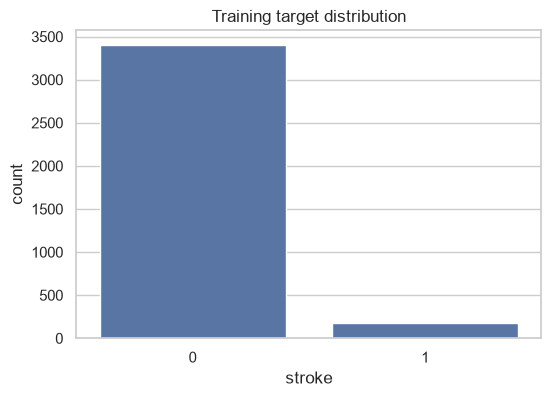

In [5]:
feature_summary = pd.DataFrame({
    "dtype": X_train.dtypes.astype(str),
    "missing_count": X_train.isna().sum(),
    "missing_percent": X_train.isna().mean().mul(100).round(2),
    "unique_count": X_train.nunique(dropna=False),
})
display(feature_summary)

target_summary = pd.DataFrame({
    "count": y_train.value_counts().sort_index(),
    "percent": y_train.value_counts(normalize=True).sort_index().mul(100).round(2),
})
display(target_summary)

plt.figure(figsize=(6, 4))
sns.countplot(x=y_train)
plt.title("Training target distribution")
plt.xlabel(TARGET)
plt.show()

### หมายเหตุเกี่ยวกับ `Unknown`

ถ้า `smoking_status` มีค่า `Unknown` จะยังเก็บเป็น category แยก ไม่เปลี่ยนเป็น NaN โดยอัตโนมัติ เพราะอาจหมายถึง “ไม่มีข้อมูลประวัติการสูบ” ซึ่งต่างจากค่าที่หายเพราะข้อผิดพลาด ต้องตัดสินใจจาก data dictionary/domain knowledge ก่อน

## 5. Build a leakage-safe pipeline

Pipeline กลางอยู่ใน `src/modeling/pipeline.py` และทำงานดังนี้:

**Numeric features**
- เติม missing ด้วย median ที่เรียนรู้จากข้อมูลตอน `fit`
- เพิ่ม missing indicator
- StandardScaler

**Categorical features**
- เติม missing ด้วยค่าที่พบบ่อยที่สุดจากข้อมูลตอน `fit`
- One-hot encoding และรองรับ category ใหม่ด้วย `handle_unknown='ignore'`

ทุกขั้นตอนอยู่ใน Pipeline เพื่อให้ cross-validation fit preprocessing ใหม่ภายในแต่ละ fold

In [6]:
baseline_pipeline = build_model_pipeline(
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE,
    )
)
baseline_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{

### ทำไมใช้ `class_weight='balanced'`?

Target stroke มีสัดส่วน positive ต่ำ การให้น้ำหนัก class ช่วยให้ baseline ไม่สนใจเฉพาะ class ใหญ่ วิธีนี้อยู่ภายใน estimator และทำงานถูกต้องในแต่ละ CV fold

ยังไม่ใช้ SMOTE ใน Phase นี้ หากทดลองภายหลัง SMOTE ต้องอยู่ใน `imblearn.Pipeline` และเกิดเฉพาะ training fold ห้าม resample ก่อนแบ่งข้อมูลหรือก่อน cross-validation

## 6. Baseline cross-validation on train only

ใช้ `StratifiedKFold` เพื่อรักษาสัดส่วน target ในแต่ละ fold นี่เป็นเพียง baseline sanity check; การเปรียบเทียบและ tune model จริงจะอยู่ใน Phase 4

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
}

cv_results = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False,
)

cv_summary = pd.DataFrame({
    metric.removeprefix("test_"): {
        "mean": np.mean(values),
        "std": np.std(values),
    }
    for metric, values in cv_results.items()
    if metric.startswith("test_")
}).T.round(4)
display(cv_summary)

,mean,std
roc_auc,0.8484,0.0189
pr_auc,0.2079,0.0142
recall,0.7990,0.0622
precision,0.1422,0.0099
f1,0.2413,0.0160


## 7. Fit baseline and inspect validation performance

Fit ด้วย train เท่านั้น แล้วตรวจ validation หนึ่งครั้ง Test ยังคงไม่ถูกเปิดใช้

> ค่า threshold 0.5 ด้านล่างเป็น baseline เท่านั้น การเลือก threshold ที่เหมาะกับต้นทุน false negative/false positive จะทำภายหลัง

In [8]:
baseline_pipeline.fit(X_train, y_train)
validation_probability = baseline_pipeline.predict_proba(X_validation)[:, 1]
validation_prediction = (validation_probability >= 0.5).astype(int)

print(f"Validation ROC-AUC: {roc_auc_score(y_validation, validation_probability):.4f}")
print(f"Validation PR-AUC:  {average_precision_score(y_validation, validation_probability):.4f}")
print("\nClassification report at threshold 0.5:")
print(classification_report(y_validation, validation_prediction, digits=4, zero_division=0))

Validation ROC-AUC: 0.8518
Validation PR-AUC:  0.2742

Classification report at threshold 0.5:
              precision    recall  f1-score   support

           0     0.9819    0.7462    0.8480       729
           1     0.1274    0.7297    0.2169        37

    accuracy                         0.7454       766
   macro avg     0.5547    0.7380    0.5324       766
weighted avg     0.9407    0.7454    0.8175       766



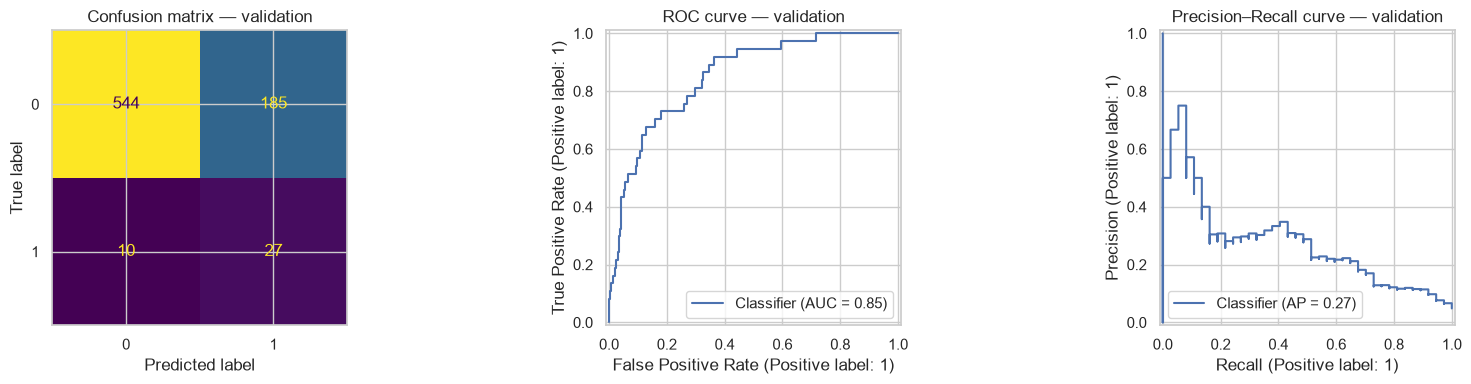

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(
    y_validation, validation_prediction, ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion matrix — validation")
RocCurveDisplay.from_predictions(y_validation, validation_probability, ax=axes[1])
axes[1].set_title("ROC curve — validation")
PrecisionRecallDisplay.from_predictions(y_validation, validation_probability, ax=axes[2])
axes[2].set_title("Precision–Recall curve — validation")
plt.tight_layout()
plt.show()

## 8. Inspect transformed feature names

ตรวจผลของ fitted preprocessor เพื่อยืนยันว่าคอลัมน์ categorical ถูก encode และ identifier ไม่หลุดเข้าโมเดล โดยไม่บันทึก transformed CSV เพราะ preprocessing ต้องอยู่กับ Pipeline

In [10]:
feature_names = baseline_pipeline.named_steps["preprocessor"].get_feature_names_out()
print(f"Input features:       {X_train.shape[1]}")
print(f"Transformed features: {len(feature_names)}")
display(pd.Series(feature_names, name="transformed_feature").to_frame())
assert "id" not in feature_names

Input features:       10
Transformed features: 22


,transformed_feature
0,age
1,hypertension
2,heart_disease
3,avg_glucose_level
4,bmi
5,missingindicator_bmi
6,gender_Female
7,gender_Male
8,gender_Other
9,ever_married_No
